In [2]:

import requests
import pandas as pd
from pathlib import Path
import time

OUT = Path("weather_downloads")
OUT.mkdir(exist_ok=True)

locations = {
    "northern_virginia_fairfax": (38.85, -77.31),
    "dallas_tx": (32.78, -96.80),
    "fort_worth_tx": (32.76, -97.33),
}

BASE_URL = "https://power.larc.nasa.gov/api/temporal/hourly/point"

START_YEAR = 2001
END_YEAR = 2026
END_DATE = "20261019"

for name, (lat, lon) in locations.items():
    yearly_data = []

    for year in range(START_YEAR, END_YEAR + 1):
        start = f"{year}0101"
        end = END_DATE if year == END_YEAR else f"{year}1231"

        params = {
            "parameters": "T2M,RH2M,PS",
            "community": "SB",
            "latitude": lat,
            "longitude": lon,
            "start": start,
            "end": end,
            "format": "JSON",
            "time-standard": "UTC",
        }

        print(f"Downloading {name}: {start} to {end}")

        for attempt in range(3):
            try:
                response = requests.get(
                    BASE_URL, params=params, timeout=180
                )
                response.raise_for_status()
                result = response.json()

                # NASA POWER JSON contains hourly values by parameter.
                properties = result["properties"]["parameter"]
                dates = list(properties["T2M"].keys())

                df = pd.DataFrame({
                    "datetime": pd.to_datetime(
                        dates, format="%Y%m%d%H"
                    ),
                    "temperature": [
                        properties["T2M"][d] for d in dates
                    ],
                    "relative_humidity": [
                        properties["RH2M"][d] for d in dates
                    ],
                    "surface_pressure": [
                        properties["PS"][d] for d in dates
                    ],
                })

                yearly_data.append(df)
                break

            except Exception as exc:
                print(f"Attempt {attempt + 1} failed: {exc}")
                if attempt == 2:
                    raise
                time.sleep(5 * (attempt + 1))

        time.sleep(1)  # Avoid hammering the API

    combined = pd.concat(yearly_data, ignore_index=True)
    combined = combined.drop_duplicates("datetime")
    combined = combined.sort_values("datetime")

    filename = OUT / f"{name}_hourly_2001_2026.csv"
    combined.to_csv(filename, index=False)

    print(f"Saved {filename}: {len(combined):,} rows")

print("All downloads complete.")


Saved weather_downloads/northern_virginia_fairfax_hourly_2001_2026.csv: 226,152 rows
Saved weather_downloads/dallas_tx_hourly_2001_2026.csv: 226,152 rows
Saved weather_downloads/fort_worth_tx_hourly_2001_2026.csv: 226,152 rows
All downloads complete.


In [6]:
# import io
# import requests
# import pandas as pd

# print("Fetching master station list from NOAA...")
# # 1. Fetch the master station list for GHCNh
# station_url = "https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/doc/ghcnh-station-list.txt"
# r = requests.get(station_url)
# r.raise_for_status()

# # 2. Parse the fixed-width file based on NOAA's standard format
# colspecs = [(0, 11), (12, 20), (21, 30), (31, 37), (38, 40), (41, 71)]
# names = ["station_id", "latitude", "longitude", "elevation", "state", "name"]
# all_stations = pd.read_fwf(io.StringIO(r.text), colspecs=colspecs, names=names)

# # OPTIONAL BUT RECOMMENDED: Filter for high-quality, continuous aviation stations
# all_stations = all_stations[all_stations['station_id'].str.startswith('USW', na=False)]

# # 3. Define your bounding boxes based on your NLDAS slices
# # Format: "prefix_name": (min_lat, max_lat, min_lon, max_lon)
# bounding_boxes = {
#     "va": (38.5, 39.5, -78.0, -77.0),
#     "tx": (32.3, 33.3, -97.5, -96.5)
# }

# selected_stations = []

# for region, (min_lat, max_lat, min_lon, max_lon) in bounding_boxes.items():
#     # Filter the master list by bounding box
#     mask = (
#         (all_stations["latitude"] >= min_lat) &
#         (all_stations["latitude"] <= max_lat) &
#         (all_stations["longitude"] >= min_lon) &
#         (all_stations["longitude"] <= max_lon)
#     )
    
#     region_stations = all_stations[mask].copy()
#     region_stations["region"] = region
    
#     # Add a dummy distance column so your downstream code doesn't break
#     region_stations["distance_km"] = 0 
    
#     selected_stations.append(region_stations)

# # 4. Create the final DataFrame your script expects
# selected = pd.concat(selected_stations, ignore_index=True)

# print(f"Found {len(selected)} high-quality stations within the bounding boxes:")
# for idx, row in selected.iterrows():
#     print(f" - {row['station_id']}: {row['name']} ({row['region']})")

# # Now your original download loop (for _, station in tqdm(selected.iterrows()...) continues below!



Fetching master station list from NOAA...
Found 38 high-quality stations within the bounding boxes:
 - USW00000367: WARRENTON FAUQUIER AP (va)
 - USW00003710: MANASSAS RGNL AP (va)
 - USW00003714: LEESBURG EXECUTIVE AP (va)
 - USW00013710: WASHINGTON DC BOLLING FLD AFB (va)
 - USW00013730: FREDERICK MUNI AP (va)
 - USW00013734: MARTINSBURG E W VIRGINIA RGNL (va)
 - USW00013743: WASHINGTON REAGAN NATL AP (va)
 - USW00013749: FREDERICK AF (va)
 - USW00013751: ANACOSTIA NAS (va)
 - USW00013773: QUANTICO MCAS (va)
 - USW00093725: WASHINGTON DC WB CITY (va)
 - USW00093728: DAVISON AAF (va)
 - USW00093734: STERLING (va)
 - USW00093738: WASHINGTON DULLES INTL AP (va)
 - USW00093764: GAITHERSBURG MONTGOMERY CO AP (va)
 - USW00093798: CULPEPER RGNL AP (va)
 - USW00003927: DAL-FTW WSCMO AP (tx)
 - USW00003970: DALLAS ADDISON AP (tx)
 - USW00003971: DALLAS REDBIRD AP (tx)
 - USW00003985: FORT WORTH SPINKS AP (tx)
 - USW00003991: DENTON MUNICPAL AP (tx)
 - USW00013907: DALLAS HENSLEY FLD AFB (tx)


In [7]:
# import io
# import time
# import pandas as pd
# import numpy as np
# import requests
# from tqdm import tqdm
# from pathlib import Path

# # ==========================================
# # SETUP & CONFIGURATION
# # ==========================================
# RAW_HOURLY = Path("raw_noaa_hourly")
# RAW_HOURLY.mkdir(exist_ok=True)
# RAW_DAILY = Path("raw_noaa_daily")
# RAW_DAILY.mkdir(exist_ok=True)
# OUT = Path("weather_downloads")
# OUT.mkdir(exist_ok=True)
# session = requests.Session()

# START_YEAR = 2002
# END_YEAR = 2026
# LATEST_DATE = pd.Timestamp("2026-10-19")

# # ==========================================
# # 1. FIND STATIONS VIA BOUNDING BOXES
# # ==========================================
# print("Fetching master station list from NOAA...")
# station_url = "https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/doc/ghcnh-station-list.txt"
# r = session.get(station_url)
# r.raise_for_status()

# colspecs = [(0, 11), (12, 20), (21, 30), (31, 37), (38, 40), (41, 71)]
# names = ["station_id", "latitude", "longitude", "elevation", "state", "name"]
# all_stations = pd.read_fwf(io.StringIO(r.text), colspecs=colspecs, names=names)

# # Filter for high-quality, continuous aviation stations (ASOS/AWOS)
# all_stations = all_stations[all_stations['station_id'].str.startswith('USW', na=False)]

# bounding_boxes = {
#     "va": (38.5, 39.5, -78.0, -77.0),
#     "tx": (32.3, 33.3, -97.5, -96.5)
# }

# selected_stations = []
# for region, (min_lat, max_lat, min_lon, max_lon) in bounding_boxes.items():
#     mask = (
#         (all_stations["latitude"] >= min_lat) &
#         (all_stations["latitude"] <= max_lat) &
#         (all_stations["longitude"] >= min_lon) &
#         (all_stations["longitude"] <= max_lon)
#     )
#     region_stations = all_stations[mask].copy()
#     region_stations["region"] = region
#     region_stations["distance_km"] = 0 
#     selected_stations.append(region_stations)

# selected = pd.concat(selected_stations, ignore_index=True)

# print(f"\nFound {len(selected)} high-quality stations within bounding boxes:")
# for idx, row in selected.iterrows():
#     print(f" - {row['station_id']}: {row['name']} ({row['region']})")


# # ==========================================
# # HELPER FUNCTIONS
# # ==========================================
# def clean_column_name(col):
#     return str(col).strip().lower().replace(" ", "_").replace("-", "_")

# def find_column(df, candidates):
#     for candidate in candidates:
#         if candidate in df.columns:
#             return candidate
#     return None


# # ==========================================
# # 2. DOWNLOAD HOURLY DATA (GHCNh)
# # ==========================================
# print("\n--- Starting HOURLY Data Pull ---")
# HOURLY_BASE = "https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/access/by-year/{year}/psv/GHCNh_{station}_{year}.psv"

# hourly_data = []
# hourly_log = []

# for _, station in tqdm(selected.iterrows(), total=len(selected), desc="Hourly Stations"):
#     station_id = str(station["station_id"]).strip()
#     region = station["region"]

#     for year in range(START_YEAR, END_YEAR + 1):
#         url = HOURLY_BASE.format(year=year, station=station_id)
#         local_file = RAW_HOURLY / f"GHCNh_{station_id}_{year}.psv"

#         try:
#             if local_file.exists() and local_file.stat().st_size > 0:
#                 content = local_file.read_bytes()
#             else:
#                 r = session.get(url, timeout=90)
#                 if r.status_code == 404:
#                     hourly_log.append({"station_id": station_id, "year": year, "status": "not available"})
#                     continue
#                 r.raise_for_status()
#                 content = r.content
#                 if not content.strip():
#                     continue
#                 local_file.write_bytes(content)

#             df = pd.read_csv(io.BytesIO(content), sep="|", dtype=str, low_memory=False)
#             df.columns = [clean_column_name(c) for c in df.columns]

#             year_col, month_col = find_column(df, ["year"]), find_column(df, ["month"])
#             day_col, hour_col = find_column(df, ["day"]), find_column(df, ["hour"])
#             minute_col = find_column(df, ["minute"])

#             if not all([year_col, month_col, day_col, hour_col]): continue

#             date_parts = (
#                 df[year_col].str.zfill(4) + df[month_col].str.zfill(2) + 
#                 df[day_col].str.zfill(2) + df[hour_col].str.zfill(2) + 
#                 (df[minute_col].str.zfill(2) if minute_col else "00")
#             )
#             df["datetime"] = pd.to_datetime(date_parts, format="%Y%m%d%H%M", errors="coerce", utc=True)

#             temp_col = find_column(df, ["temperature", "dry_bulb_temperature", "dry_bulb_temp"])
#             rh_col = find_column(df, ["relative_humidity", "rh"])
#             pressure_col = find_column(df, ["station_level_pressure", "station_pressure", "surface_pressure"])

#             if temp_col is None or rh_col is None or pressure_col is None: continue
            
#             part = pd.DataFrame({
#                 "datetime": df["datetime"],
#                 "station_id": station_id,
#                 "station_name": station["name"],
#                 "region": region,
#                 "latitude": station["latitude"],   # <--- ADD THIS
#                 "longitude": station["longitude"], # <--- ADD THIS
#                 "temperature_raw": pd.to_numeric(df[temp_col], errors="coerce"),
#                 "relative_humidity_raw": pd.to_numeric(df[rh_col], errors="coerce"),
#                 "station_pressure_raw": pd.to_numeric(df[pressure_col], errors="coerce"),
#             })
#             # Clean nulls (NOAA uses -9999 or -999 for missing)
#             for col in ["temperature_raw", "relative_humidity_raw", "station_pressure_raw"]:
#                 part[col] = part[col].mask(part[col] <= -999)

#             # Filter dates
#             part = part[part["datetime"].notna() & (part["datetime"].dt.year >= START_YEAR) & (part["datetime"] <= LATEST_DATE + pd.Timedelta(days=1))]
            
#             if not part.empty:
#                 hourly_data.append(part)
#                 hourly_log.append({"station_id": station_id, "year": year, "status": f"downloaded {len(part)} rows"})

#         except Exception as exc:
#             hourly_log.append({"station_id": station_id, "year": year, "status": f"ERROR: {exc}"})
#         time.sleep(0.15)

# if hourly_data:
#     weather_h = pd.concat(hourly_data, ignore_index=True)
#     weather_h = weather_h.drop_duplicates(["station_id", "datetime"]).sort_values(["region", "station_id", "datetime"])
#     weather_h.to_csv(OUT / "noaa_hourly_observations.csv", index=False)
#     pd.DataFrame(hourly_log).to_csv(OUT / "hourly_download_log.csv", index=False)
#     print(f"Saved {len(weather_h):,} HOURLY observations.")


# # ==========================================
# # 3. DOWNLOAD DAILY DATA (GHCNd)
# # ==========================================
# print("\n--- Starting DAILY Data Pull ---")
# # NOAA provides daily data in one single CSV per station! Much faster.
# DAILY_BASE = "https://www.ncei.noaa.gov/data/global-historical-climatology-network-daily/access/{station}.csv"

# daily_data = []

# for _, station in tqdm(selected.iterrows(), total=len(selected), desc="Daily Stations"):
#     station_id = str(station["station_id"]).strip()
#     region = station["region"]
#     url = DAILY_BASE.format(station=station_id)
#     local_file = RAW_DAILY / f"GHCNd_{station_id}.csv"

#     try:
#         if local_file.exists() and local_file.stat().st_size > 0:
#             df = pd.read_csv(local_file, dtype=str, low_memory=False)
#         else:
#             r = session.get(url, timeout=90)
#             if r.status_code == 404:
#                 print(f"Daily data not found for {station_id}")
#                 continue
#             r.raise_for_status()
#             local_file.write_bytes(r.content)
#             df = pd.read_csv(io.BytesIO(r.content), dtype=str, low_memory=False)

#         # Process Daily Data
#         df["DATE"] = pd.to_datetime(df["DATE"], errors="coerce")
#         df = df[
#             (df["DATE"].dt.year >= START_YEAR) & 
#             (df["DATE"] <= LATEST_DATE)
#         ].copy()

#         if df.empty:
#             continue

#         # Extract useful daily columns if they exist (TMAX, TMIN, PRCP)
#        # Extract useful daily columns if they exist (TMAX, TMIN, PRCP)
#         part_d = pd.DataFrame({
#             "date": df["DATE"],
#             "station_id": station_id,
#             "station_name": station["name"],
#             "region": region,
#             "latitude": station["latitude"],   # <--- ADD THIS
#             "longitude": station["longitude"], # <--- ADD THIS
#         })
        
#         if "TMAX" in df.columns: part_d["tmax"] = pd.to_numeric(df["TMAX"], errors="coerce")
#         if "TMIN" in df.columns: part_d["tmin"] = pd.to_numeric(df["TMIN"], errors="coerce")
#         if "TAVG" in df.columns: part_d["tavg"] = pd.to_numeric(df["TAVG"], errors="coerce")
#         if "PRCP" in df.columns: part_d["precip"] = pd.to_numeric(df["PRCP"], errors="coerce")

#         daily_data.append(part_d)
        
#     except Exception as exc:
#         print(f"Error fetching daily data for {station_id}: {exc}")
        
#     time.sleep(1) # Prevent API rate limits

# if daily_data:
#     weather_d = pd.concat(daily_data, ignore_index=True)
#     weather_d = weather_d.sort_values(["region", "station_id", "date"])
#     weather_d.to_csv(OUT / "noaa_daily_observations.csv", index=False)
#     print(f"Saved {len(weather_d):,} DAILY observations.")

# print("\nAll downloads complete. Files saved to the 'weather_downloads' directory.")

Fetching master station list from NOAA...

Found 38 high-quality stations within bounding boxes:
 - USW00000367: WARRENTON FAUQUIER AP (va)
 - USW00003710: MANASSAS RGNL AP (va)
 - USW00003714: LEESBURG EXECUTIVE AP (va)
 - USW00013710: WASHINGTON DC BOLLING FLD AFB (va)
 - USW00013730: FREDERICK MUNI AP (va)
 - USW00013734: MARTINSBURG E W VIRGINIA RGNL (va)
 - USW00013743: WASHINGTON REAGAN NATL AP (va)
 - USW00013749: FREDERICK AF (va)
 - USW00013751: ANACOSTIA NAS (va)
 - USW00013773: QUANTICO MCAS (va)
 - USW00093725: WASHINGTON DC WB CITY (va)
 - USW00093728: DAVISON AAF (va)
 - USW00093734: STERLING (va)
 - USW00093738: WASHINGTON DULLES INTL AP (va)
 - USW00093764: GAITHERSBURG MONTGOMERY CO AP (va)
 - USW00093798: CULPEPER RGNL AP (va)
 - USW00003927: DAL-FTW WSCMO AP (tx)
 - USW00003970: DALLAS ADDISON AP (tx)
 - USW00003971: DALLAS REDBIRD AP (tx)
 - USW00003985: FORT WORTH SPINKS AP (tx)
 - USW00003991: DENTON MUNICPAL AP (tx)
 - USW00013907: DALLAS HENSLEY FLD AFB (tx)
 - 

Hourly Stations:  13%|█▎        | 5/38 [03:38<24:03, 43.75s/it]


KeyboardInterrupt: 

In [18]:
import pandas as pd
from pathlib import Path

# Change this to point to any specific PSV file in your raw_noaa_hourly folder
sample_file = Path("raw_noaa_hourly/GHCNh_USW00000367_2008.psv")

if not sample_file.exists():
    print(f"File not found: {sample_file}")
else:
    # Read the pipe-separated file
    df = pd.read_csv(sample_file, sep="|", dtype=str, low_memory=False)
    
    print(f"--- FILE LOADED ---")
    print(f"Total Rows: {len(df):,}")
    print(f"Total Columns: {len(df.columns)}")
    
    # These are the standard names NOAA uses in these files
    # We will grab the main values and their associated quality flags
    cols_to_examine = [
        "DATE", 
        "temperature", "temperature_Quality_Code", 
        "dew_point_temperature", "dew_point_temperature_Quality_Code",
        "relative_humidity", "relative_humidity_Quality_Code",
        "station_level_pressure", "station_level_pressure_Quality_Code"
    ]
    
    # Only keep the columns that actually exist in this specific file
    available_cols = [c for c in cols_to_examine if c in df.columns]
    
    print("\n--- FIRST 5 ROWS (Selected Columns) ---")
    print(df[available_cols].head())
    
    print("\n--- MISSING DATA COUNT ---")
    # Check how many times the value is missing or flagged as -9999
    for col in available_cols:
        if "Quality" not in col and col != "DATE":
            # Count blanks/NaNs and -9999 values
            missing = df[col].isna().sum() + (df[col] == "-9999").sum() + (df[col] == "-999").sum()
            print(f"{col}: {missing:,} missing records out of {len(df):,}")
            
    print("\n--- QUALITY FLAG BREAKDOWN (Temperature) ---")
    if "temperature_Quality_Code" in df.columns:
        # Fill NaNs with "BLANK (Passed QC)" so it makes sense to read
        qc_counts = df["temperature_Quality_Code"].fillna("BLANK (Passed QC)").value_counts()
        print(qc_counts)

--- FILE LOADED ---
Total Rows: 24,735
Total Columns: 329

--- FIRST 5 ROWS (Selected Columns) ---
                  DATE temperature temperature_Quality_Code  \
0  2008-01-15T23:00:00         0.0                        1   
1  2008-01-15T23:20:00         0.0                        1   
2  2008-01-15T23:40:00        -1.0                        1   
3  2008-01-16T05:00:00        -5.0                        1   
4  2008-01-16T11:00:00        -4.0                        1   

  dew_point_temperature dew_point_temperature_Quality_Code relative_humidity  \
0                  -8.0                                  1                55   
1                  -8.0                                  1                55   
2                  -8.0                                  1                59   
3                  -8.0                                  1                80   
4                  -7.0                                  1                80   

  relative_humidity_Quality_Code station_

Loading and preparing data...
Generating plot...


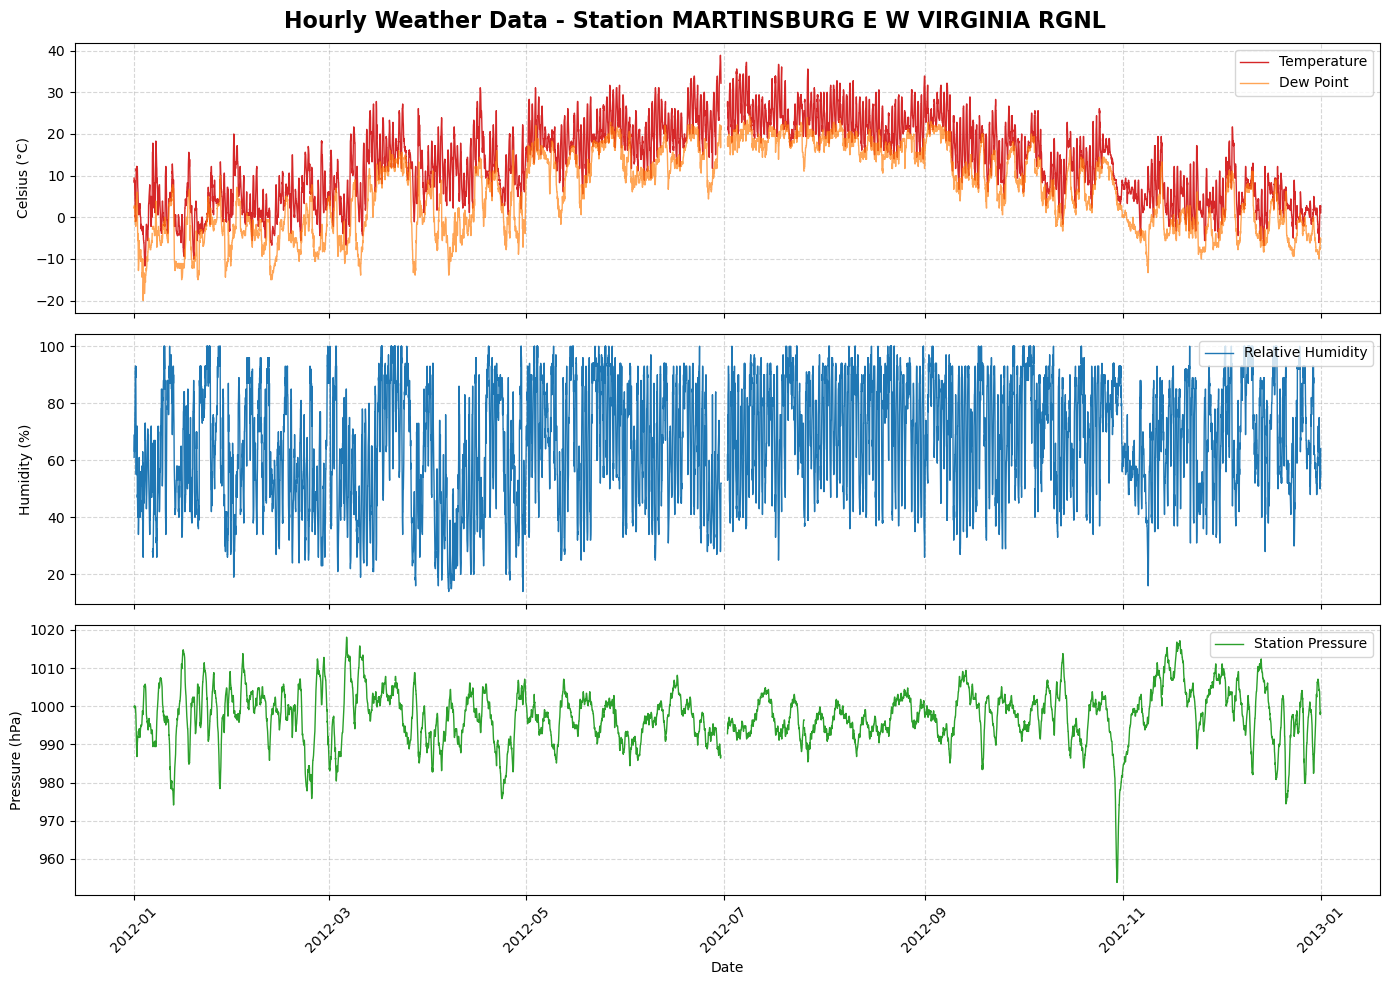

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Point to your sample file
sample_file = Path("raw_noaa_hourly/GHCNh_USW00013734_2012.psv")

if not sample_file.exists():
    print(f"File not found: {sample_file}. Please check the path.")
else:
    print("Loading and preparing data...")
    # Load the data
    df = pd.read_csv(sample_file, sep="|", dtype=str, low_memory=False)
    
    # 2. Parse the Date
    df["DATE"] = pd.to_datetime(df["DATE"], errors="coerce")
    
    # 3. Define the columns we want to plot
    cols_to_plot = {
        "temperature": "Temperature (°C)", 
        "dew_point_temperature": "Dew Point (°C)",
        "relative_humidity": "Relative Humidity (%)", 
        "station_level_pressure": "Station Pressure (hPa)"
    }
    
    # 4. Clean the data (Convert to numeric and turn -9999 into NaN so it doesn't break the plot)
    for col in cols_to_plot.keys():
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
            # Replace -999 and -9999 with NaN (Not a Number) for plotting
            df.loc[df[col] <= -999, col] = np.nan
            
    # Sort by date just in case
    df = df.sort_values("DATE")
    
    # Optional: If plotting a whole year is too noisy, uncomment the line below to plot just one month (e.g., July)
    # df = df[df["DATE"].dt.month == 7]

    print("Generating plot...")
    # 5. Create a stacked plot (3 rows, 1 column) sharing the same X-axis
    fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
    fig.suptitle(f"Hourly Weather Data - Station {df['Station_name'].iloc[0]}", fontsize=16, fontweight='bold')

    # --- Plot 1: Temperature & Dew Point ---
    if "temperature" in df.columns:
        axes[0].plot(df["DATE"], df["temperature"], label="Temperature", color="tab:red", linewidth=1)
    if "dew_point_temperature" in df.columns:
        axes[0].plot(df["DATE"], df["dew_point_temperature"], label="Dew Point", color="tab:orange", alpha=0.7, linewidth=1)
    axes[0].set_ylabel("Celsius (°C)")
    axes[0].legend(loc="upper right")
    axes[0].grid(True, linestyle="--", alpha=0.5)

    # --- Plot 2: Relative Humidity ---
    if "relative_humidity" in df.columns:
        axes[1].plot(df["DATE"], df["relative_humidity"], label="Relative Humidity", color="tab:blue", linewidth=1)
    axes[1].set_ylabel("Humidity (%)")
    axes[1].legend(loc="upper right")
    axes[1].grid(True, linestyle="--", alpha=0.5)

    # --- Plot 3: Station Pressure ---
    if "station_level_pressure" in df.columns:
        axes[2].plot(df["DATE"], df["station_level_pressure"], label="Station Pressure", color="tab:green", linewidth=1)
    axes[2].set_ylabel("Pressure (hPa)")
    axes[2].legend(loc="upper right")
    axes[2].grid(True, linestyle="--", alpha=0.5)

    # Format the layout
    plt.xlabel("Date")
    plt.xticks(rotation=45)
    plt.tight_layout()
    
    # Show the plot!
    plt.show()

In [21]:
import pandas as pd
import numpy as np
import requests
import io
import re
from pathlib import Path
import time
from tqdm import tqdm

OUT = Path("uscrn_independent_data")
OUT.mkdir(exist_ok=True)

# ==========================================
# CONFIGURATION
# ==========================================
START_YEAR = 2002
END_YEAR = 2026

# Put state abbreviations here to only download specific states (e.g., ["TX", "VA"]). 
# Leave the list empty [] to download ALL 130+ stations across the entire USA!
STATES_TO_PULL = [] 

# ==========================================
# 1. AUTO-DISCOVER STATION NAMES
# ==========================================
print("Connecting to NOAA to discover active USCRN stations...")
# We check a recent year (2023) to see all stations that are actively reporting
dir_url = "https://www.ncei.noaa.gov/pub/data/uscrn/products/hourly02/2023/"
r_dir = requests.get(dir_url, timeout=30)
r_dir.raise_for_status()

# Use regex to extract the exact station names from the file list
# NOAA files look like: CRNH0203-2023-TX_Palestine_6_WNW.txt
found_stations = list(set(re.findall(r'CRNH0203-2023-(.*?)\.txt', r_dir.text)))
found_stations.sort()

# Filter by state if requested
if STATES_TO_PULL:
    # The station string always starts with the state abbreviation (e.g., "TX_...")
    uscrn_stations = [s for s in found_stations if s.split('_')[0] in STATES_TO_PULL]
else:
    uscrn_stations = found_stations

print(f"Found {len(uscrn_stations)} stations to process!")
if STATES_TO_PULL:
    print(f"Filtered to states: {STATES_TO_PULL}")

# ==========================================
# 2. DOWNLOAD DATA
# ==========================================
all_uscrn = []

# Using tqdm to show a progress bar since 130 stations will take about 15-20 minutes
for station in tqdm(uscrn_stations, desc="Downloading USCRN Stations"):
    station_data = []
    
    for year in range(START_YEAR, END_YEAR + 1):
        url = f"https://www.ncei.noaa.gov/pub/data/uscrn/products/hourly02/{year}/CRNH0203-{year}-{station}.txt"
        
        try:
            r = requests.get(url, timeout=30)
            if r.status_code == 404:
                continue # Station didn't exist in this specific year, skip silently
            r.raise_for_status()
            
            # Use header=None to prevent Pandas from shifting columns 
            df = pd.read_csv(io.StringIO(r.text), sep=r'\s+', header=None, dtype=str)
            
            # Combine date and time strings safely
            date_strings = df[1] + df[2].str.zfill(4)
            df['datetime'] = pd.to_datetime(date_strings, format='%Y%m%d%H%M', errors='coerce', utc=True)
            
            # Drop rows where the timestamp was broken
            df = df.dropna(subset=['datetime']).copy()
            
            if df.empty:
                continue
                
            # Extract exactly the columns we need using NOAA's index
            clean_df = pd.DataFrame({
                'datetime': df['datetime'],
                'station_name': station,
                'latitude': pd.to_numeric(df[7], errors='coerce'),
                'longitude': pd.to_numeric(df[6], errors='coerce'),
                'temperature': pd.to_numeric(df[8], errors='coerce'),
                'relative_humidity': pd.to_numeric(df[21], errors='coerce'),
                'precipitation': pd.to_numeric(df[12], errors='coerce')
            })
            
            # Clean NOAA's -9999 missing data flags
            for col in ['latitude', 'longitude', 'temperature', 'relative_humidity', 'precipitation']:
                clean_df.loc[clean_df[col] <= -999, col] = np.nan
                
            station_data.append(clean_df)
            
        except Exception as e:
            pass # Silently pass to avoid cluttering the progress bar
            
        time.sleep(0.15) # Be polite to NOAA servers
        
    if station_data:
        st_df = pd.concat(station_data, ignore_index=True)
        # Drop duplicates and sort
        st_df = st_df.drop_duplicates(subset=['datetime']).sort_values('datetime')
        st_df.to_csv(OUT / f"{station}_USCRN_hourly.csv", index=False)
        all_uscrn.append(st_df)

# ==========================================
# 3. SAVE MASTER FILE
# ==========================================
if all_uscrn:
    final_uscrn = pd.concat(all_uscrn, ignore_index=True)
    final_uscrn.to_csv(OUT / "all_uscrn_independent_observations.csv", index=False)
    print(f"\nAll USCRN downloads complete! Total rows: {len(final_uscrn):,}")
    print(f"Master file saved to: {OUT / 'all_uscrn_independent_observations.csv'}")
else:
    print("\nNo data was downloaded.")

Connecting to NOAA to discover active USCRN stations...
Found 159 stations to process!



All USCRN downloads complete! Total rows: 28,025,081
Master file saved to: uscrn_independent_data/all_uscrn_independent_observations.csv
